# 16 模糊 C 均值聚类

> **模块**：模糊数学 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、matplotlib、scikit-fuzzy

## 1. 问题背景

传统的聚类分析是一种硬划分（例如K-Means聚类），它把每个待辨识的对象严格地划分到某类中，具有“非此即彼”的性质，因此这种类别划分的界限是分明的。然而实际上大多数对象并没有严格的属性，它们在性质和类属方面存在着中介性，具有“亦此亦彼”的性质，因此适合进行软划分。

Zadeh提出的模糊集理论为这种软划分提供了有力的分析工具，人们开始用模糊方法来处理聚类问题，并称之为模糊聚类分析。模糊聚类得到了样本属于各个类别的不确定性程度，表达了样本类属的中介性，建立起了样本对于类别的不确定性的描述，能更客观地反映现实世界，从而成为聚类分析研究的主流。

在众多模糊聚类算法中，模糊C均值（FCM，Fuzzy C—Means）算法应用最广泛且较成功，它通过优化目标函数得到每个样本点对所有类中心的隶属度，从而决定样本点的类属以达到自动对样本数据进行分类的目的。


## 2. 学习目标

- 掌握模糊 C 均值聚类算法原理
- 掌握模糊 C 均值聚类算法实现


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 模糊 C 均值聚类算法原理

K-Means算法与模糊聚类算法对比：
- k均值聚类：一种硬聚类算法，隶属度只有两个取值0或1，提出的基本根据是“类内误差平方和最小化”准则；
- 模糊C均值聚类算法：一种模糊聚类算法，是k均值聚类算法的推广形式，隶属度取值为[0,1]区间内的任何一个数，提出的基本根据是“类内加权误差平方和最小化”准则。

#### 4.1.1 模糊 C 均值聚类算法基本思想

设总样本集 $G = \{ω_j,j=1,2,...,n\}$ 是 $n$ 个样本组成的集合，$C$ 为预定的类别数目，$m_i(i=1,2,...,C)$ 为每个聚类的中心，$μ_{ij}$ 表示样本 $ω_j$ 对第 $i$ 类的隶属度，用隶属度定义的聚类损失函数为：

$$
J_f = \sum_{j=1}^{n}\sum_{i=1}^{C}{{μ_{ij}}^m{||ω_j-m_i||}^2}

$$

- 其中，$m>1$ 是一个可以控制聚类结果的模糊程度的常数

在不同隶属度定义方法下，最小化损失函数 $J_f$，就得到不同的模糊聚类方法。

模糊C均值聚类方法要求一个样本对于各个类别的隶属度之和为1，即：

$$
\sum_{i=1}^{C}{μ_{ij}}=1

$$

此时求 $J_f$ 的极小值，可以先求 $J_f$ 对 $μ_{ij}$ 和 $m_i$ 偏导数，令其为0，得到 $μ_{ij}$ 的解析式：

$$
μ_{ij} = \frac{{\left(\frac{1}{||ω_j-m_i||}\right)}^{\frac{2}{m-1}}}{\sum_{k=1}^{C}{\left(\frac{1}{||ω_j-m_k||}\right)}^{\frac{2}{m-1}}} \tag{1}

$$
$$
m_i = \frac{\sum_{j=1}^{n}{μ_{ij}^mω_j}}{\sum_{j=1}^{n}{μ_{ij}^m}} \tag{2}

$$

#### 4.1.2 模糊 C 均值聚类算法步骤

1. 初始化，设定聚类数目 $C(2≤C≤n)$ 和参数 $m$，设总样本集 $G$，样本数 $n$，要将样本集 $G$ 划分为 $C$ 类，记为 $G_1, G_2, ..., G_C$，初始化 $C$ 个聚类中心，记为 $m_1, m_2, ..., m_C$。
2. 重复下面的运算，直到各聚类中心稳定。

$\quad\quad$ 2.1 用当前的聚类中心根据(1)式计算隶属度

$\quad\quad$ 2.2 用当前隶属度按(2)式更新计算各聚类中心 $m_1, m_2, ..., m_C$

当算法收敛时，就得到了各类的聚类中心和各个样本对于各类的隶属度值，从而完成了模糊聚类。

### 4.2 模糊 C 均值聚类算法实现

**例1**. 已知聚类的指标变量为 $x_1, x_2$，四个样本点的数据分别为：

$$
ω_1 = (1,3),\quad\quadω_2 = (1.4,3.1),\quad\quadω_3 = (1.2,2.7),\quad\quadω_4 = (3,1)

$$

使用模糊C均值聚类分析把样本点分成两类。

**分析**：设模糊C均值聚类算法损失函数 $J_f$ 中参数 $m=2$，聚类数目 $C=2$，分为 $G_1, G_2$ 两类

设初始四个样本分类情况为： $G_1=\{ω_1,ω_2,ω_3\}, G_2=\{ω_4\}$，初始所有样本的隶属度如下：

$$
\begin{cases}
μ_{11}=1, & μ_{21}=0 \\
μ_{12}=1, & μ_{22}=0 \\
μ_{13}=1, & μ_{23}=0 \\
μ_{14}=0, & μ_{24}=1
\end{cases}

$$

此时，计算 $G_1,G_2$ 两类的聚类中心。

$$
m_i = \frac{\sum_{j=1}^{n}{μ_{ij}^mω_j}}{\sum_{j=1}^{n}{μ_{ij}^m}} \tag{2}

$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
# 用来正常显示中文标签
plt.rcParams['font.sans-serif']=['SimHei'] 
# 正常显示负号
plt.rc('axes',unicode_minus=False)
# 忽略警告提示
import warnings
warnings.filterwarnings('ignore')
from skfuzzy.cluster import cmeans,cmeans_predict
# 创建样本数据w
w = np.array([[1,3.2],
              [1.4,3.1],
              [1.2,2.7],
              [3,1]])
# 创建初始样本隶属度
a1 = np.array([1,1,1,0])
a2 = np.array([0,0,0,1])
# 计算G1类聚类中心坐标
# 初始聚类坐标根据聚类中心公式计算
m1_x1 = np.matmul(w[:,0],a1)/sum(a1)
m1_x2 = np.matmul(w[:,1],a1)/sum(a1)
print('G1类聚类中心坐标：({})'.format((m1_x1,m1_x2)))
# 计算G2类聚类中心坐标
m2_x1 = np.matmul(w[:,0],a2)/sum(a2)
m2_x2 = np.matmul(w[:,1],a2)/sum(a2)
print('G2类聚类中心坐标：({})'.format((m2_x1,m2_x2)))

G1类聚类中心坐标：((np.float64(1.2), np.float64(3.0)))
G2类聚类中心坐标：((np.float64(3.0), np.float64(1.0)))


然后再计算每个样本点分别到 $G_1, G_2$ 类中心的距离（欧氏距离）。

$$
d = ||\omega_j - m_k||^{\frac{2}{m-1}}

$$

In [2]:
def Euclidean_d(y1,y2):
    '''
    计算两点间欧式距离
    '''
    d = np.sqrt((y1[0]-y2[0])**2+(y1[1]-y2[1])**2)
    return d
# 计算每个样本分别到两类聚类中心的距离
# dij表示第j个样本到第i类聚类中心的距离
d11 = Euclidean_d(w[0],np.array([m1_x1,m1_x2]))
d12 = Euclidean_d(w[1],np.array([m1_x1,m1_x2]))
d13 = Euclidean_d(w[2],np.array([m1_x1,m1_x2]))
d14 = Euclidean_d(w[3],np.array([m1_x1,m1_x2]))

d21 = Euclidean_d(w[0],np.array([m2_x1,m2_x2]))
d22 = Euclidean_d(w[1],np.array([m2_x1,m2_x2]))
d23 = Euclidean_d(w[2],np.array([m2_x1,m2_x2]))
d24 = Euclidean_d(w[3],np.array([m2_x1,m2_x2]))

计算四个样本点对$G_1$类和$G_2$类的隶属度。

$$μ_{ij} = \frac{{(\frac{1}{||ω_j-m_i||})}^{\frac{2}{m-1}}}{\sum_{k=1}^{C}{{(\frac{1}{||ω_j-m_k||})}^{\frac{2}{m-1}}}} \tag{1}$$

In [3]:
# dij表示第j个样本对两类距离倒数平方和，也就是隶属度公式的分母
di1 = 1/(d11)**2+1/(d21)**2
di2 = 1/(d12)**2+1/(d22)**2
di3 = 1/(d13)**2+1/(d23)**2
di4 = 1/(d14)**2+1/(d24)**2

# aij表示第j个样本对第i类的隶属度
a11 = (1/(d11)**2)/di1
a12 = (1/(d12)**2)/di2
a13 = (1/(d13)**2)/di3
a14 = (1/(d14)**2)/di4

# 本实验只有两类，并且每个样本对所有类别隶属度加和为1
a21 = 1-a11
a22 = 1-a12
a23 = 1-a13
a24 = 1-a14

# 得到四个样本对于G1，G2的隶属度
a1 = np.array([a11,a12,a13,a14])
a2 = np.array([a21,a22,a23,a24])
print('四个样本对于G1的隶属度：',a1)
print('四个样本对于G2的隶属度：',a2)
a = np.vstack((a1,a2)).T
print('根据隶属度最大原则，四个样本聚类结果为：',np.argmax(a,axis=1))

四个样本对于G1的隶属度： [0.99103139 0.99287749 0.98553055 0.        ]
四个样本对于G2的隶属度： [0.00896861 0.00712251 0.01446945 1.        ]
根据隶属度最大原则，四个样本聚类结果为： [0 0 0 1]


In [4]:
# 计算G1类聚类中心坐标
# 初始聚类坐标根据聚类中心公式计算
m1_x1 = np.matmul(w[:,0],a1)/sum(a1)
m1_x2 = np.matmul(w[:,1],a1)/sum(a1)
print('G1类聚类中心坐标：({})'.format((m1_x1,m1_x2)))
# 计算G2类聚类中心坐标
m2_x1 = np.matmul(w[:,0],a2)/sum(a2)
m2_x2 = np.matmul(w[:,1],a2)/sum(a2)
print('G2类聚类中心坐标：({})'.format((m2_x1,m2_x2)))

G1类聚类中心坐标：((np.float64(1.200124340151514), np.float64(3.0006179157282027)))
G2类聚类中心坐标：((np.float64(2.9462639569214706), np.float64(1.0575281833069745)))


计算此时的损失函数$J_f$

$$J_f = \sum_{j=1}^{n}\sum_{i=1}^{C}{{μ_{ij}}^m{||ω_j-m_i||}^2}$$

In [5]:
# 计算四个样本与G1和G2聚类中心距离
d1 = []
for i in range(4):
    d = Euclidean_d(w[i],np.array([m1_x1,m1_x2]))
    d1.append(d)
d2 = []
for i in range(4):
    d = Euclidean_d(w[i],np.array([m2_x1,m2_x2]))
    d2.append(d)
# 距离×（更新后）隶属度**m（m=2）
Jf = np.matmul(d1,a1**2)+np.matmul(d2,a2**2)
print('此时损失函数值为：',Jf)

此时损失函数值为： 0.8690684964163818


接下来，判断算法是否收敛，设允许的误差是$\epsilon=1\%$，若隶属度

$$|U^{(k+1)}-U^{(k)}|<\epsilon$$

In [6]:
a1_int = [1,1,1,0]
a2_int = [0,0,0,1]
if (a1_int-a1).all()<0.01 and (a2_int-a2).all()<0.01:
    print('在误差允许范围内，聚类结束')

在误差允许范围内，聚类结束


聚类算法收敛，聚类结束。
样本$ω_1,ω_2,ω_3$聚为一类，
样本$ω_4$聚为一类

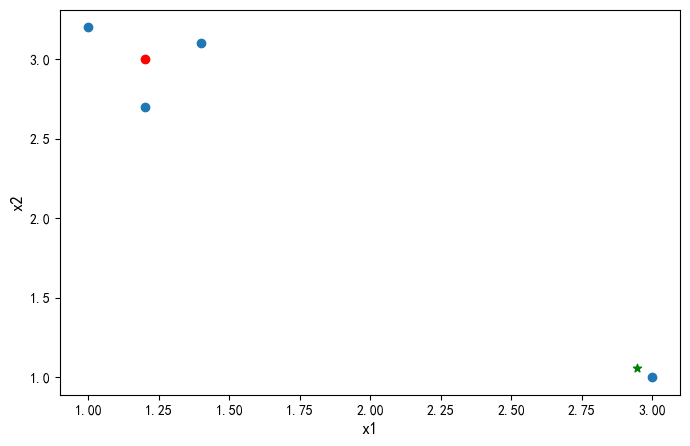

In [7]:
# 绘图
plt.figure(figsize=(8,5))
# 绘制原始数据的散点图
plt.scatter(w[:,0],w[:,1])
# 绘制两个聚类中心点
plt.scatter(m1_x1,m1_x2,c = 'r',marker='o')
plt.scatter(m2_x1,m2_x2,c = 'g',marker='*')
plt.xlabel('x1',fontsize=12)
plt.ylabel('x2',fontsize=12)
plt.show()

### 4.3 模糊 C 均值聚类算法 skfuzzy 实现

模糊C均值聚类算法：`skfuzzy.cluster.cmeans(data, c, m, error, ...)`

- **data**: 数据，shape：(S, N)。N为数据集的个数；S是每个样本向量内的特征个数。
- **c**: 期望的簇或类的数量。
- **m**: 在每次迭代时隶属函数中的参数。
- **error**: 误差，停止准则；如果 `(u[p] - u[p-1])` 的范数 < `error`，则提前停止。
- **Maxiter**: 允许的最大迭代次数。

函数返回：
- **center**: 聚类中心坐标。
- **u**: 隶属度。
- **u0**: 隶属度的初始猜测（提供初始化，如果没有提供初始化，则使用随机猜测）。
- **d**: 最终的欧氏距离矩阵。

In [8]:
# 定义数据
w = np.array([[1,3.2],
              [1.4,3.1],
              [1.2,2.7],
              [3,1]])
# 放入数据，聚成两类，m=2，误差=0.001
cntr,u, u0, d, _, _, _ = cmeans(data = w.T,
                               c = 2,
                               m = 2,
                               error = 0.001, 
                               maxiter = 1000)

print('聚类中心为：\n',cntr)
print('隶属度初始值为：\n',u0)
print('根据隶属度最大原则，四个样本聚类结果为：',np.argmax(u.T,axis=1))
print('最终样本距离聚类中心距离为：\n',d)

聚类中心为：
 [[2.99937747 1.00064231]
 [1.2002515  3.00126338]]
隶属度初始值为：
 [[0.29095709 0.59993835 0.61441627 0.58711914]
 [0.70904291 0.40006165 0.38558373 0.41288086]]
根据隶属度最大原则，四个样本聚类结果为： [1 1 1 0]
最终样本距离聚类中心距离为：
 [[2.97231972e+00 2.63918756e+00 2.47499007e+00 8.94487915e-04]
 [2.82129238e-01 2.22819177e-01 3.01263482e-01 2.69149583e+00]]


## 5. 小结

本次实验介绍了模糊C均值聚类算法的原理和一般步骤。基于一个例子，使用自定义函数和skfuzzyAPI实现了对样本的模糊C均值聚类。

通过本次实验需要掌握以下内容：
- 掌握模糊C均值聚类算法原理
- 掌握模糊C均值聚类算法实现